# 4 · Simulating tracer transport on the brain mesh

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/albgirelli/gonzo-viewer/blob/main/notebooks/04_mesh_simulation.ipynb)

The tetrahedral mesh (≈100 000 vertices) covers the brain. Each vertex carries the measured tracer
concentration at each time, and the **boundary concentration** (the concentration in the CSF next to
the brain surface). This lets us run a *data-driven* simulation: impose the measured CSF concentration
on the surface, solve a PDE inside, and compare with the measured interior.

Here: pure diffusion $\partial_t c = D\,\Delta c$ with P1 finite elements (scikit-fem) and backward Euler.
Runs in about 30 s.

In [1]:
!pip install -q scikit-fem 2>/dev/null || true

In [2]:
# Setup: works both locally (inside the cloned repository) and on Google Colab.
from pathlib import Path
import subprocess

REPO_URL = "https://github.com/albgirelli/gonzo-viewer"
if Path("../data/regions.csv").exists():
    DATA = Path("../data")
else:
    if not Path("gonzo-viewer").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL], check=True)
    DATA = Path("gonzo-viewer/data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
import scipy.sparse.linalg as spla
from skfem import MeshTet, Basis, ElementTetP1, asm
from skfem.models.poisson import laplace, mass

m = np.load(DATA / "mesh/gonzo_mesh.npz")
print({k: m[k].shape for k in m.files})
mesh = MeshTet(np.ascontiguousarray(m["points"].T, dtype=float), np.ascontiguousarray(m["tetrahedra"].T))
basis = Basis(mesh, ElementTetP1())
K, M = asm(laplace, basis), asm(mass, basis)
boundary = mesh.boundary_nodes()
interior = np.setdiff1d(np.arange(mesh.nvertices), boundary)
hours, c_data, c_bdry = m["hours"], m["concentration"], m["boundary_concentration"]
# subdomains (per cell): 1 cortical grey matter, 2 white matter, 3 subcortical grey matter

{'points': (99755, 3), 'tetrahedra': (492359, 4), 'subdomains': (492359,), 'parcellations': (492359,), 'mean_diffusivity': (492359,), 'fractional_anisotropy': (492359,), 'diffusion_tensor': (492359, 3, 3), 'concentration': (5, 99755), 'boundary_concentration': (5, 99755), 'hours': (5,)}


In [4]:
def simulate(D, alpha=1.0, dt=0.5):
    """D in mm²/s; boundary value alpha * measured CSF concentration. Returns solution at the scan times."""
    A = (M + dt * D * 3600 * K).tocsr()
    lu = spla.splu(A[interior][:, interior].tocsc())
    A_ib = A[interior][:, boundary]
    c, out = np.zeros(mesh.nvertices), {0: np.zeros(mesh.nvertices)}
    for t in np.arange(dt, hours[-1] + dt / 2, dt):
        # linear interpolation in time between scans (hat-function weights)
        w = np.maximum(0, 1 - np.abs(np.interp(t, hours, np.arange(len(hours))) - np.arange(len(hours))))
        cb = alpha * (w @ c_bdry[:, boundary])
        c[interior] = lu.solve((M @ c)[interior] - A_ib @ cb)
        c[boundary] = cb
        for k, h in enumerate(hours):
            if abs(t - h) < dt / 2:
                out[k] = c.copy()
    return np.array([out.get(k, c) for k in range(len(hours))])

sim = simulate(D=1.2e-4)

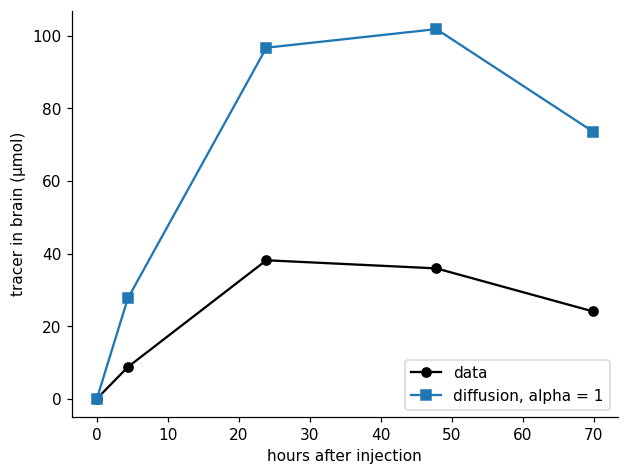

In [5]:
def amount(c):
    """Total tracer in the brain in µmol (concentration in mmol/L × volume in mL)."""
    return (M @ c).sum() / 1000

plt.plot(hours, [amount(c) for c in c_data], "ko-", label="data")
plt.plot(hours, [amount(c) for c in sim], "C0s-", label="diffusion, alpha = 1")
plt.xlabel("hours after injection"); plt.ylabel("tracer in brain (µmol)"); plt.legend();

The simulation puts far too much tracer into the brain. **Why?** Think about what the boundary
condition means: the CSF concentration is a concentration *in fluid*, while an MRI voxel in tissue reports
tracer per *tissue* volume, and only the extracellular space (≈ 20%) is accessible.

Try `simulate(D, alpha)` with other values, compare region by region, and look at the solution in ParaView:

In [6]:
import meshio
cells = [("tetra", m["tetrahedra"])]
meshio.write("simulation.vtu", meshio.Mesh(m["points"], cells, point_data={
    **{f"data_{h:.0f}h": c_data[k] for k, h in enumerate(hours)},
    **{f"sim_{h:.0f}h": sim[k] for k, h in enumerate(hours)},
}, cell_data={"subdomain": [m["subdomains"]]}))
print("wrote simulation.vtu (open in ParaView)")

wrote simulation.vtu (open in ParaView)


## Ideas
* **Estimate** $D$ and $\alpha$ (and maybe a clearance rate) from the data: an inverse problem with a PDE constraint.
* Use the **diffusion tensor** (`m["diffusion_tensor"]`, per cell) to make diffusion anisotropic. Does it matter?
* Different parameters in **grey and white matter** (`m["subdomains"]`).
* Add a **velocity field** (e.g. from a Darcy model) and see whether advection improves the fit.
* Mesh refinement, time step, and other numerical questions: how accurate is the simulation itself?